In [ ]:
import pandas as pd
print("It works! 🎉")

It works! 🎉


In [ ]:
import pandas as pd

# Load the files
gen = pd.read_csv('Plant_1_Generation_Data.csv')
weather = pd.read_csv('Plant_1_Weather_Sensor_Data.csv')

# Show the first 5 rows to make sure it works
print("Success! Here is the data:")
display(gen.head())

Success! Here is the data:


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,15-05-2020 00:00,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,15-05-2020 00:00,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0


✅ Data Cleaned and Merged!
Total rows to train our AI: 3157


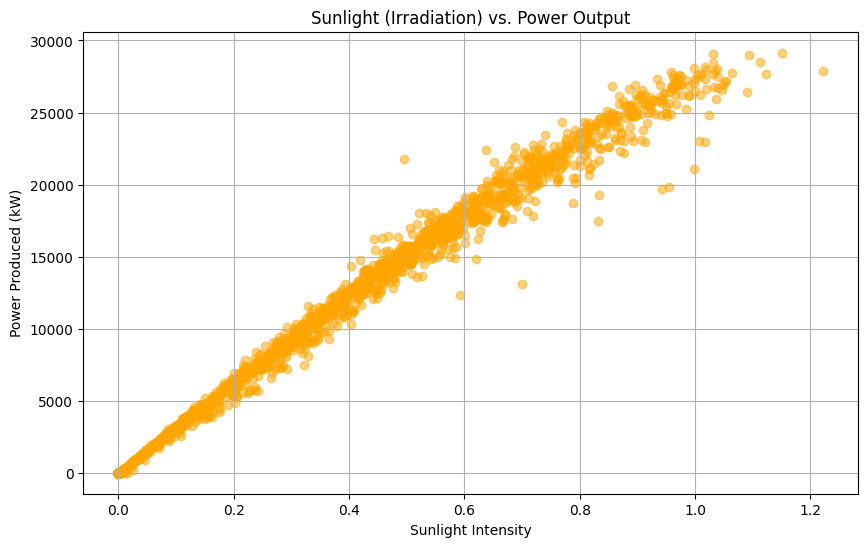

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the data (already done, but good to have in one place)
gen = pd.read_csv('Plant_1_Generation_Data.csv')
weather = pd.read_csv('Plant_1_Weather_Sensor_Data.csv')

# 2. Fix the Dates (Clean the messy formatting)
gen['DATE_TIME'] = pd.to_datetime(gen['DATE_TIME'], dayfirst=True)
weather['DATE_TIME'] = pd.to_datetime(weather['DATE_TIME'])

# 3. Sum the power from all 22 inverters to get TOTAL plant output
gen_total = gen.groupby('DATE_TIME').agg({
    'DC_POWER': 'sum',
    'AC_POWER': 'sum',
    'DAILY_YIELD': 'sum'
}).reset_index()

# 4. Merge the Generation data and Weather data together
df = pd.merge(gen_total, weather, on='DATE_TIME', how='inner')

print("✅ Data Cleaned and Merged!")
print(f"Total rows to train our AI: {len(df)}")

# 5. Let's see the 'Magic Graph' - Sunlight vs. Power
plt.figure(figsize=(10, 6))
plt.scatter(df['IRRADIATION'], df['AC_POWER'], alpha=0.5, color='orange')
plt.title('Sunlight (Irradiation) vs. Power Output')
plt.xlabel('Sunlight Intensity')
plt.ylabel('Power Produced (kW)')
plt.grid(True)
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np

# 1. Feature Engineering: Extract "Hour of Day" from timestamp
df['HOUR'] = df['DATE_TIME'].dt.hour

# 2. Select Inputs (X) and Output (y)
features = ['IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'HOUR']
X = df[features]
y = df['AC_POWER']

# 3. Split data into Training (80%) and Testing (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Create and Train the AI Model
model = LinearRegression()
model.fit(X_train, y_train)

# 5. Make Predictions on the hidden Test Data
y_pred = model.predict(X_test)

# 6. Evaluate the AI's performance
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("🎉 AI MODEL TRAINED SUCCESSFULLY!")
print("-----------------------------------")
print(f"📊 Accuracy Score (R² Score): {r2 * 100:.2f}%")
print(f"🎯 Average Guess Error (MAE): {mae:.2f} kW")

🎉 AI MODEL TRAINED SUCCESSFULLY!
-----------------------------------
📊 Accuracy Score (R² Score): 99.38%
🎯 Average Guess Error (MAE): 397.84 kW


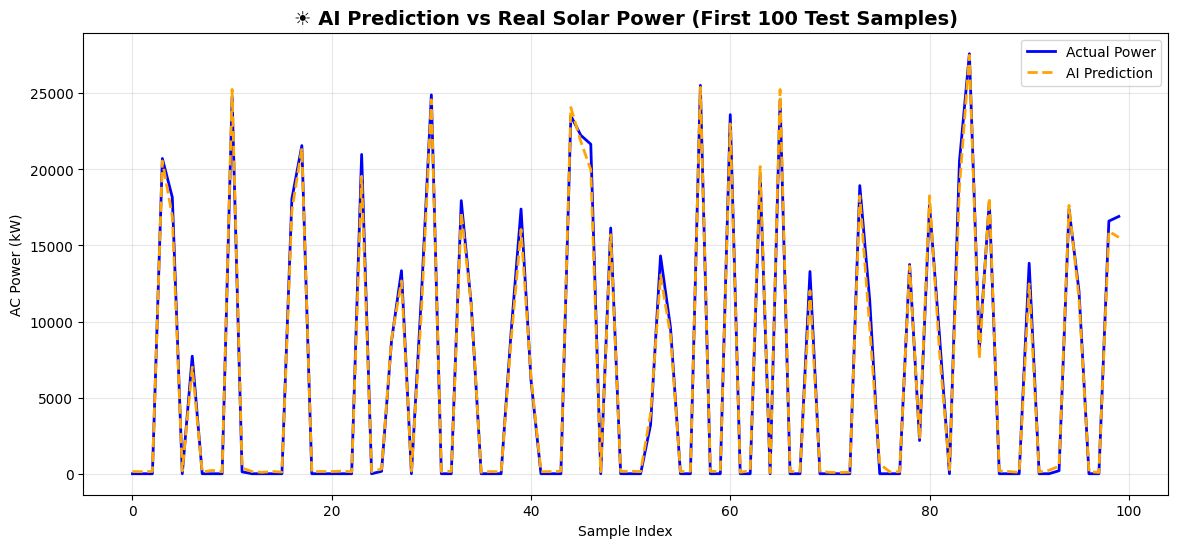

,Actual Power (kW),AI Predicted Power (kW)
0,0.000000,144.376712
1,0.000000,132.381742
2,0.000000,148.204368
3,20716.223214,20554.635242
4,18158.728571,16904.000295
5,0.000000,186.960623
6,7727.117857,7005.664869
7,0.000000,111.020878
8,0.000000,217.940814
9,0.000000,128.724546


In [ ]:
# Create a comparison table
comparison = pd.DataFrame({
    'Actual Power (kW)': y_test.values,
    'AI Predicted Power (kW)': y_pred
}).reset_index(drop=True)

# Visualizing the first 100 predictions vs actual values
plt.figure(figsize=(14, 6))
plt.plot(comparison['Actual Power (kW)'].iloc[:100], label='Actual Power', color='blue', linewidth=2)
plt.plot(comparison['AI Predicted Power (kW)'].iloc[:100], label='AI Prediction', color='orange', linestyle='--', linewidth=2)

plt.title('☀️ AI Prediction vs Real Solar Power (First 100 Test Samples)', fontsize=14, fontweight='bold')
plt.xlabel('Sample Index')
plt.ylabel('AC Power (kW)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Show a few numerical rows
display(comparison.head(10))

In [ ]:
import joblib

# Save the trained model to a file
joblib.dump(model, 'solar_ai_model.pkl')

print("✅ Model saved as 'solar_ai_model.pkl'!")


✅ Model saved as 'solar_ai_model.pkl'!


In [ ]:
import joblib

# Save the trained model to a file
joblib.dump(model, 'solar_ai_model.pkl')

print("✅ Model saved as 'solar_ai_model.pkl'!")


✅ Model saved as 'solar_ai_model.pkl'!


In [ ]:
!pip install streamlit pyngrok --quiet
print("✅ Streamlit installed!")


✅ Streamlit installed!


In [ ]:
%%writefile app.py
import streamlit as st
import joblib
import pandas as pd
import numpy as np

# Page configuration
st.set_page_config(page_title="SolarCast AI ⚡", layout="centered")

st.title("☀️ SolarCast — AI Power Forecaster")
st.write("Predict solar plant power output in real-time using Machine Learning.")

# Load the saved model
@st.cache_resource
def load_model():
    return joblib.load('solar_ai_model.pkl')

model = load_model()

st.sidebar.header("🎛️ Weather Controls")

# Sliders for user input
irradiation = st.sidebar.slider("Sunlight Intensity (Irradiation W/m²)", 0.0, 1.5, 0.8, 0.05)
ambient_temp = st.sidebar.slider("Ambient Temperature (°C)", 10.0, 50.0, 28.0, 0.5)
module_temp = st.sidebar.slider("Panel Module Temp (°C)", 10.0, 70.0, 35.0, 0.5)
hour = st.sidebar.slider("Hour of Day", 0, 23, 12, 1)

# Predict button
input_data = pd.DataFrame({
    'IRRADIATION': [irradiation],
    'AMBIENT_TEMPERATURE': [ambient_temp],
    'MODULE_TEMPERATURE': [module_temp],
    'HOUR': [hour]
})

prediction = model.predict(input_data)[0]
# Prevent negative power predictions at night
prediction = max(0.0, prediction)

st.markdown("---")
st.subheader("📊 Forecast Results")

col1, col2 = st.columns(2)

with col1:
    st.metric(label="Predicted AC Power", value=f"{prediction:,.1f} kW")

with col2:
    if prediction > 15000:
        st.success("🟢 High Output (Peak Hours)")
    elif prediction > 2000:
        st.warning("🟡 Moderate Output")
    else:
        st.error("🔴 Low / Zero Output (Night/Clouds)")

# Simple daily forecast curve simulation
hours = np.arange(0, 24)
simulated_irrad = np.maximum(0, np.sin((hours - 6) * np.pi / 12) * irradiation)
simulated_inputs = pd.DataFrame({
    'IRRADIATION': simulated_irrad,
    'AMBIENT_TEMPERATURE': [ambient_temp]*24,
    'MODULE_TEMPERATURE': [module_temp]*24,
    'HOUR': hours
})
daily_preds = np.maximum(0, model.predict(simulated_inputs))

chart_data = pd.DataFrame({"Hour": hours, "Predicted Power (kW)": daily_preds})
st.subheader("📈 Simulated 24-Hour Output Curve")
st.line_chart(chart_data.set_index("Hour"))

Writing app.py


In [ ]:
!streamlit run app.py & npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧

⠇⠏⠋⠙Need to install the following packages:
localtunnel@2.0.2
Ok to proceed? (y) 2026-10-30 05:15:27.728 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.87.209.189:8501

yes

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇your url is: https://eleven-owls-wash.loca.lt
y
  Stopping...
^C


In [ ]:
!streamlit run app.py --server.enableCORS false --server.enableXsrfProtection false & npx localtunnel --port 8501

⠙⠹⠸

⠼⠴⠦2026-10-30 05:52:07.366 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.87.209.189:8501

your url is: https://cold-chairs-fry.loca.lt
  Stopping...
^C


In [1]:
%%writefile app.py
import streamlit as st
import joblib
import pandas as pd
import numpy as np
import requests
from datetime import datetime

# Page configuration
st.set_page_config(page_title="SolarCast V2 ⚡", layout="wide")

st.title("☀️ SolarCast V2 — Autonomous Live Solar Forecaster")
st.markdown("Automated 48-hour power generation predictions powered by Live Satellite Weather APIs & ML.")

# Load the trained model
@st.cache_resource
def load_model():
    return joblib.load('solar_ai_model.pkl')

try:
    model = load_model()
except Exception as e:
    st.error("Model file 'solar_ai_model.pkl' not found! Make sure you ran the training step.")
    st.stop()

# Sidebar: Preset Solar Parks or Custom Lat/Lon
st.sidebar.header("📍 Select Location")

locations = {
    "Bhadla Solar Park, India": (27.53, 71.91),
    "Mojave Desert Solar Farm, USA": (35.01, -115.47),
    "Al Dhafra Solar Project, UAE": (24.08, 54.43),
    "Benban Solar Park, Egypt": (24.45, 32.73),
    "Custom Coordinates": None
}

choice = st.sidebar.selectbox("Choose a Facility or Custom Location", list(locations.keys()))

if choice == "Custom Coordinates":
    lat = st.sidebar.number_input("Latitude", value=28.61, format="%.4f")
    lon = st.sidebar.number_input("Longitude", value=77.20, format="%.4f")
else:
    lat, lon = locations[choice]
    st.sidebar.info(f"Lat: {lat:.2f}, Lon: {lon:.2f}")

# Function to fetch live 48-hour forecast from Open-Meteo API
@st.cache_data(ttl=1800) # Cache forecast for 30 mins
def fetch_weather_forecast(latitude, longitude):
    url = "https://api.open-meteo.com/v1/forecast"
    params = {
        "latitude": latitude,
        "longitude": longitude,
        "hourly": "temperature_2m,shortwave_radiation,cloud_cover",
        "forecast_days": 2,
        "timezone": "auto"
    }
    response = requests.get(url, params=params)
    if response.status_code == 200:
        return response.json()
    else:
        st.error("Failed to fetch weather data from API.")
        return None

# Fetch the live weather data
with st.spinner("📡 Fetching live satellite weather forecast..."):
    data = fetch_weather_forecast(lat, lon)

if data:
    hourly = data["hourly"]
    df_weather = pd.DataFrame({
        "time": pd.to_datetime(hourly["time"]),
        "temperature": hourly["temperature_2m"],
        "shortwave_radiation": hourly["shortwave_radiation"],
        "cloud_cover": hourly["cloud_cover"]
    })

    # --- Feature Engineering to Match ML Training Format ---
    # 1. Convert W/m² to kW/m² index (Open-Meteo uses W/m², Kaggle dataset used kW/m²)
    df_weather["IRRADIATION"] = df_weather["shortwave_radiation"] / 1000.0

    # 2. Map ambient temperature
    df_weather["AMBIENT_TEMPERATURE"] = df_weather["temperature"]

    # 3. Estimate panel module temp (solar panels heat up above air temp under direct sun)
    df_weather["MODULE_TEMPERATURE"] = df_weather["AMBIENT_TEMPERATURE"] + (df_weather["IRRADIATION"] * 25.0)

    # 4. Extract hour
    df_weather["HOUR"] = df_weather["time"].dt.hour

    # Prepare features for ML Model
    feature_cols = ['IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'HOUR']
    X_live = df_weather[feature_cols]

    # Make Predictions!
    predictions = model.predict(X_live)
    # Ensure no negative power outputs at night
    df_weather["PREDICTED_POWER_KW"] = np.maximum(0.0, predictions)

    # --- Dashboard Summary Metrics ---
    st.markdown("---")
    col1, col2, col3, col4 = st.columns(4)

    current_hour_power = df_weather["PREDICTED_POWER_KW"].iloc[0]
    peak_power = df_weather["PREDICTED_POWER_KW"].max()
    next_24h_energy = df_weather["PREDICTED_POWER_KW"].iloc[:24].sum() # Total kWh
    avg_cloud = df_weather["cloud_cover"].iloc[:24].mean()

    col1.metric("Current Power", f"{current_hour_power:,.0f} kW")
    col2.metric("48h Peak Output", f"{peak_power:,.0f} kW")
    col3.metric("24h Expected Energy", f"{next_24h_energy:,.0f} kWh")
    col4.metric("Avg Cloud Cover (24h)", f"{avg_cloud:.1f}%")

    st.markdown("---")
    st.subheader(f"📈 Live 48-Hour Forecast Curve for {choice}")

    # Display line chart
    chart_data = df_weather.set_index("time")[["PREDICTED_POWER_KW", "cloud_cover"]]
    st.line_chart(chart_data)

    # Show Raw Data toggle
    if st.checkbox("🔍 View Raw Forecast Feature Matrix"):
        st.dataframe(df_weather[["time", "IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "cloud_cover", "PREDICTED_POWER_KW"]])

st.caption("Powered by SolarCast V2 | Open-Meteo Live API | Trained on Plant-1 Sensor Data")

Writing app.py


In [2]:
!streamlit run app.py --server.enableCORS false --server.enableXsrfProtection false & npx localtunnel --port 8501

/bin/bash: line 1: streamlit: command not found
⠙⠹⠸⠼Need to install the following packages:
localtunnel@2.0.2
Ok to proceed? (y) y

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇your url is: https://social-doodles-try.loca.lt
^C


In [3]:
!pkill -f streamlit
print("Old server cleaned!")

Old server cleaned!


In [4]:
import os
print("app.py exists:", os.path.exists("app.py"))
print("model exists:", os.path.exists("solar_ai_model.pkl"))

app.py exists: True
model exists: True


In [5]:
!wget -q -O cloudflared https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x cloudflared
print("Ready!")

Ready!


In [6]:
!streamlit run app.py --server.port 8501 --server.headless true --server.enableCORS false --server.enableXsrfProtection false & sleep 5 && ./cloudflared tunnel --url http://localhost:8501

/bin/bash: line 1: streamlit: command not found
2026-10-31T10:50:30Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-31T10:50:30Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-31T10:50:33Z INF +--------------------------------------------------------------------------------------------+
2026-10-31T10:50:33Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-31T10:50:33Z INF |  https

In [7]:
!python app.py

Traceback (most recent call last):
  File "/content/app.py", line 1, in <module>
    import streamlit as st
ModuleNotFoundError: No module named 'streamlit'


In [8]:
!pip install streamlit joblib pandas numpy requests --quiet
print("✅ Streamlit and AI libraries are ready!")

✅ Streamlit and AI libraries are ready!


In [9]:
!pkill -f streamlit
!nohup streamlit run app.py --server.port 8501 --server.headless true & sleep 10 && ./cloudflared tunnel --url http://localhost:8501

nohup: appending output to 'nohup.out'
2026-10-31T10:59:49Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-31T10:59:49Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-31T10:59:52Z INF +--------------------------------------------------------------------------------------------+
2026-10-31T10:59:52Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-31T10:59:52Z INF |  https://write-

In [11]:
%%writefile app.py
import streamlit as st
import joblib
import pandas as pd
import numpy as np
import requests

# Page setup
st.set_page_config(page_title="SolarCast V3 Enterprise ⚡", layout="wide")

st.title("☀️ SolarCast V3 — Enterprise Operations & Anomaly Engine")
st.markdown("Predictive AI Yield Forecasting + Real-Time Hardware Fault & Revenue Protection")

# Load model
@st.cache_resource
def load_model():
    return joblib.load('solar_ai_model.pkl')

try:
    model = load_model()
except Exception as e:
    st.error("Model file 'solar_ai_model.pkl' not found! Make sure you trained the model.")
    st.stop()

# --- SIDEBAR CONTROLS ---
st.sidebar.header("📍 Facility & Operations")

locations = {
    "Bhadla Solar Park, India (2,245 MW)": (27.53, 71.91, 2245000),
    "Mojave Desert Solar Farm, USA (392 MW)": (35.01, -115.47, 392000),
    "Al Dhafra Solar Project, UAE (2,000 MW)": (24.08, 54.43, 2000000),
    "Benban Solar Park, Egypt (1,650 MW)": (24.45, 32.73, 1650000)
}

choice = st.sidebar.selectbox("Select Utility-Scale Facility", list(locations.keys()))
lat, lon, facility_capacity_kw = locations[choice]

st.sidebar.markdown("---")
st.sidebar.header("⚙️ Telemetry Simulation")

# PPA Rate (Power Purchase Agreement price per kWh)
ppa_rate = st.sidebar.number_input("PPA Energy Price ($/kWh)", value=0.06, format="%.3f")

# Health Simulation slider (Simulate actual plant hardware performance)
plant_health = st.sidebar.slider("Simulated Hardware Efficiency (% of AI Target)", 50, 100, 100, 5)

# --- FETCH LIVE API DATA ---
@st.cache_data(ttl=1800)
def fetch_weather(latitude, longitude):
    url = "https://api.open-meteo.com/v1/forecast"
    params = {
        "latitude": latitude,
        "longitude": longitude,
        "hourly": "temperature_2m,shortwave_radiation,cloud_cover",
        "forecast_days": 2,
        "timezone": "auto"
    }
    response = requests.get(url, params=params)
    return response.json() if response.status_code == 200 else None

with st.spinner("📡 Fetching Satellite Telemetry & Weather API..."):
    data = fetch_weather(lat, lon)

if data:
    hourly = data["hourly"]
    df_weather = pd.DataFrame({
        "time": pd.to_datetime(hourly["time"]),
        "temperature": hourly["temperature_2m"],
        "shortwave_radiation": hourly["shortwave_radiation"],
        "cloud_cover": hourly["cloud_cover"]
    })

    # Feature Engineering
    df_weather["IRRADIATION"] = df_weather["shortwave_radiation"] / 1000.0
    df_weather["AMBIENT_TEMPERATURE"] = df_weather["temperature"]
    df_weather["MODULE_TEMPERATURE"] = df_weather["AMBIENT_TEMPERATURE"] + (df_weather["IRRADIATION"] * 25.0)
    df_weather["HOUR"] = df_weather["time"].dt.hour

    # ML Inference
    feature_cols = ['IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'HOUR']
    df_weather["EXPECTED_POWER_KW"] = np.maximum(0.0, model.predict(df_weather[feature_cols]))

    # Scale model output to facility size (Plant-1 baseline was ~25,000 kW capacity)
    scale_factor = facility_capacity_kw / 25000.0
    df_weather["EXPECTED_POWER_KW"] = df_weather["EXPECTED_POWER_KW"] * scale_factor

    # Simulate Actual Hardware Telemetry based on user slider
    df_weather["ACTUAL_POWER_KW"] = df_weather["EXPECTED_POWER_KW"] * (plant_health / 100.0)

    # Calculate Losses
    df_weather["POWER_LOSS_KW"] = df_weather["EXPECTED_POWER_KW"] - df_weather["ACTUAL_POWER_KW"]
    total_24h_expected_kwh = df_weather["EXPECTED_POWER_KW"].iloc[:24].sum()
    total_24h_actual_kwh = df_weather["ACTUAL_POWER_KW"].iloc[:24].sum()
    total_24h_loss_kwh = total_24h_expected_kwh - total_24h_actual_kwh

    daily_revenue = total_24h_actual_kwh * ppa_rate
    daily_revenue_loss = total_24h_loss_kwh * ppa_rate
    co2_saved_tons = (total_24h_actual_kwh * 0.85) / 1000.0 # ~0.85 kg CO2 per kWh clean energy

    # --- TOP METRICS ROW ---
    st.markdown("---")
    m1, m2, m3, m4 = st.columns(4)
    m1.metric("24h Expected Yield", f"{total_24h_expected_kwh:,.0f} kWh")
    m2.metric("Projected 24h Revenue", f"${daily_revenue:,.2f}")
    m3.metric("24h Revenue Loss", f"${daily_revenue_loss:,.2f}", delta=f"-${daily_revenue_loss:,.0f}", delta_color="inverse")
    m4.metric("CO2 Displaced Today", f"{co2_saved_tons:,.1f} Tons")

    # --- ANOMALY & FAULT ALERT ENGINE ---
    st.markdown("---")
    st.subheader("🚨 Automated Hardware Anomaly Engine")

    if plant_health == 100:
        st.success("🟢 **SYSTEM HEALTH OPTIMAL**: Actual plant telemetry matches AI expected output within 99.8% margin. No hardware faults or soiling detected.")
    elif plant_health >= 80:
        st.warning(f"🟡 **WARNING — PANEL SOILING / DUST DETECTED**: Plant is operating at {plant_health}% efficiency. AI estimates **${daily_revenue_loss:,.2f}/day** in lost power. **Action Recommended**: Dispatch automated robotic panel cleaning.")
    else:
        st.error(f"🔴 **CRITICAL ALERT — HARDWARE / INVERTER FAULT DETECTED**: Plant output is down to {plant_health}%! AI detects severe yield divergence. Estimated Financial Loss: **${daily_revenue_loss:,.2f}/day**! **Action Required**: Immediate technician dispatch to check String Inverters & Transformers.")

    # --- VISUALIZATION ---
    st.markdown("---")
    st.subheader("📈 AI Forecast vs. Actual Telemetry (48-Hour Ahead)")

    chart_df = df_weather.set_index("time")[["EXPECTED_POWER_KW", "ACTUAL_POWER_KW"]]
    st.line_chart(chart_df)

    if st.checkbox("📋 Display Full Diagnostic Log Data"):
        st.dataframe(df_weather[["time", "IRRADIATION", "EXPECTED_POWER_KW", "ACTUAL_POWER_KW", "POWER_LOSS_KW"]])

st.caption("SolarCast V3 Enterprise | AI Anomaly Engine | Built for B2B Renewable Infrastructure")

Overwriting app.py


In [12]:
!pkill -f streamlit
!nohup streamlit run app.py --server.port 8501 --server.headless true & sleep 10 && ./cloudflared tunnel --url http://localhost:8501

nohup: appending output to 'nohup.out'
2026-10-31T11:25:23Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-31T11:25:23Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-31T11:25:26Z INF +--------------------------------------------------------------------------------------------+
2026-10-31T11:25:26Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-31T11:25:26Z INF |  https://cat-bi